# Imports

In [1]:
import os
import time
import random
import yaml
import cv2
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from ultralytics import YOLO
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection import ssd300_vgg16
from torchvision.transforms import functional as F
from torch.utils.data import DataLoader
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

%matplotlib inline

# Pathing and Configuration

In [2]:
WS_PATH = os.path.dirname(os.getcwd())
SRC_PATH = os.path.join(WS_PATH, 'src')
DATA_PATH = os.path.join(SRC_PATH, 'dataset_yolo')
TEST_IMAGE_DIR = os.path.join(DATA_PATH, 'images', 'test')
TRAIN_RESULT_PATH = os.path.join(SRC_PATH, 'training_results')
RUNS_PATH = os.path.join(TRAIN_RESULT_PATH, 'runs')
YAML_PATH = os.path.join(DATA_PATH, 'data.yaml')
COCO_PATH = os.path.join(SRC_PATH, 'coco')
ANNOTATION_PATH = os.path.join(COCO_PATH, 'instances_test.json')

CONF_THRESHOLD = 0.25
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
NUM_CLASSES = 56 + 1  # + 1 background

print(DEVICE)

cuda


# Functions

## Plot Functions

### Plot Training Result Curve

In [3]:
# YOLO training curves
def plot_training_curves(results_csv_path: str, model_name: str):
    
    # Read training result as dataframe
    df = pd.read_csv(results_csv_path)

    epochs = df['epoch']

    # Loss curve line plot
    plt.figure()
    plt.plot(epochs, df['train/box_loss'], label='train_box', color='blue')
    plt.plot(epochs, df['train/cls_loss'], label='train_cls', color='green')
    plt.plot(epochs, df['train/dfl_loss'], label='train_dfl', color='orange')

    plt.plot(epochs, df['val/box_loss'], linestyle='--', label='val_box', color='blue')
    plt.plot(epochs, df['val/cls_loss'], linestyle='--', label='val_cls', color='green')
    plt.plot(epochs, df['val/dfl_loss'], linestyle='--', label='val_dfl', color='orange')

    plt.title(f'{model_name} Loss Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Evaluation metrics curve line pLot
    plt.figure()
    plt.plot(epochs, df['metrics/precision(B)'], label='precision')
    plt.plot(epochs, df['metrics/recall(B)'], label='recall')
    plt.plot(epochs, df['metrics/mAP50(B)'], label='mAP50')
    plt.plot(epochs, df['metrics/mAP50-95(B)'], label='mAP50-95')

    plt.title(f'{model_name} Metrics Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

In [4]:
# Faster RCNN and SSD training curves
def plot_other_training_curves(results_csv_path: str, model_name: str):
    
    # Read training result as dataframe
    df = pd.read_csv(results_csv_path)

    epochs = df['epoch']

    # Loss curve line plot
    plt.figure()
    plt.plot(epochs, df['train_loss'], label='train_loss', color='blue')
    plt.plot(epochs, df['val_loss'], label='val_loss', color='orange')

    plt.title(f'{model_name} Loss Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Evaluation metrics curve line pLot
    plt.figure()
    plt.plot(epochs, df['val_precision'], label='precision')
    plt.plot(epochs, df['val_recall'], label='recall')
    plt.plot(epochs, df['val_map50'], label='mAP50')
    plt.plot(epochs, df['val_map50_95'], label='mAP50-95')

    plt.title(f'{model_name} Metrics Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

### Plot Training Results by Comparison

In [ ]:
def plot_training_comparison(results_csv_paths: list[str], model_names: list[str]):
    color = sns.color_palette('tab10')  # Custom color

    # Loss curves line plot
    plt.figure(figsize=(10, 6))

    for i in range(len(model_names)):

        # Read training result as dataframe
        df = pd.read_csv(results_csv_paths[i])
        
        epochs = df['epoch']
        name = model_names[i]

        if name not in ('Faster RCNN', 'SSD'):
            df['train/total_loss'] = (
                df['train/box_loss'] + df['train/cls_loss'] + df['train/dfl_loss']
            )
            df['val/total_loss'] = (
                df['val/box_loss'] + df['val/cls_loss'] + df['val/dfl_loss']
            )
            display_target = [
                'epoch', 'train/total_loss',
                'val/total_loss', 'metrics/mAP50-95(B)'
            ]
            

        else:
            df['train/total_loss'] = df['train_loss']
            df['val/total_loss'] = df['val_loss']
            display_target = [
                'epoch', 'train/total_loss', 'val/total_loss', 'val_map50_95'
            ]

        print('Model :', model_names[i])
        display_df = pd.concat([df.head(), df.tail(1)])
        display_df = display_df[display_target]
        display(display_df)

        plt.plot(epochs, df['train/total_loss'], label=f'{name}/train_loss', c=color[i], alpha=0.9)
        plt.plot(epochs, df['val/total_loss'], label=f'{name}/val_loss', linestyle='--', c=color[i], alpha=0.6)

    plt.title(f'Model Loss Curves')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

    # mAP50-95 curves line pLot
    plt.figure(figsize=(10, 6))

    for i in range(len(model_names)):

        # Read training result as dataframe
        df = pd.read_csv(results_csv_paths[i])
        
        epochs = df['epoch']
        name = model_names[i]

        if name not in ('Faster RCNN', 'SSD'):
            plt.plot(
                epochs,
                df['metrics/mAP50-95(B)'],
                label=f'{name}/mAP50-95',
                c=color[i],
                alpha=0.9
            )
        
        else:
            plt.plot(
                epochs,
                df['val_map50_95'],
                label=f'{name}/mAP50-95',
                c=color[i],
                alpha=0.9
            )

    plt.title(f'Model mAP50-95 Curves')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

### Plot Confusion Matrix on Test Set

In [6]:
def plot_confusion_matrix(confusion_matrix: np.matrix, model_name: str):
    labels = confusion_matrix.to_df()['Predicted']
    cm = confusion_matrix.matrix.T
    fig, ax = plt.subplots(figsize=(14,14))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False
    )

    plt.title(f'Confusion Matrix of {model_name} Model', fontsize=18)
    plt.show()

In [7]:
def plot_other_confusion_matrix(confusion_matrix: pd.DataFrame, model_name: str):
    labels = confusion_matrix.index
    cm = confusion_matrix.values
    fig, ax = plt.subplots(figsize=(14,14))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False
    )

    plt.title(f'Confusion Matrix of {model_name} Model', fontsize=18)
    plt.show()

## Evaluation Computation Functions

### Get The Evaluation Metrics on Test Set

In [8]:
def evaluate_model(model_path: str, model_name: str, yaml_path: str):

    # Predict the test set and evaluate the predictions
    model = YOLO(model_path)
    metrics = model.val(
        data=yaml_path, split='test', exist_ok=True,
        project=RUNS_PATH, name=model_name
    )

    # Get model's evaluation metrics
    precision = np.mean(metrics.box.p)
    recall = np.mean(metrics.box.r)
    map50 = metrics.box.map50
    map5095 = metrics.box.map
    f1 = np.mean(metrics.box.f1)
    latency = metrics.speed['inference']
    confusion_matrix = metrics.confusion_matrix
    
    return {
        'precision': precision,
        'recall': recall,
        'mAP50': map50,
        'mAP50-95': map5095,
        'f1-score': f1,
        'latency': latency,
        'confusion': confusion_matrix
    }

In [9]:
def compute_iou(box1, box2):
    """
    Format:
    [x1, y1, x2, y2]
    """

    xA = max(box1[0], box2[0])
    yA = max(box1[1], box2[1])
    xB = min(box1[2], box2[2])
    yB = min(box1[3], box2[3])

    inter_w = max(0, xB - xA)
    inter_h = max(0, yB - yA)

    inter_area = inter_w * inter_h

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    union = area1 + area2 - inter_area

    if union <= 0:
        return 0

    return inter_area / union

In [10]:
# Load COCO
coco_gt = COCO(ANNOTATION_PATH)
image_ids = coco_gt.getImgIds()
cat_ids = coco_gt.getCatIds()
categories = coco_gt.loadCats(cat_ids)

cat_id_to_idx = {
    cat["id"]: idx
    for idx, cat in enumerate(categories)
}

idx_to_cat_id = {
    idx: cat["id"]
    for idx, cat in enumerate(categories)
}

CLASS_NAMES = [cat["name"] for cat in categories]

BACKGROUND = "background"
CM_CLASSES = CLASS_NAMES + [BACKGROUND]
BACKGROUND_IDX = len(CLASS_NAMES)

IOU_THRESHOLD = 0.5


def evaluate_other_model(model, model_name: str):
    model.to(DEVICE)
    model.eval()
    predictions_coco = []

    y_true = []
    y_pred = []

    inference_times = []

    # Predict each test data
    for image_id in tqdm(image_ids, desc='Test Prediction'):
        image_info = coco_gt.loadImgs(image_id)[0]
        image_path = os.path.join(TEST_IMAGE_DIR, image_info["file_name"])
        image = Image.open(image_path).convert("RGB")
        image_tensor = F.to_tensor(image).to(DEVICE)

        # Inference time
        start_time = time.time()

        with torch.no_grad():
            outputs = model([image_tensor])

        end_time = time.time()
        latency = (end_time - start_time) * 1000
        inference_times.append(latency)
        output = outputs[0]

        # Ground Truth
        ann_ids = coco_gt.getAnnIds(imgIds=image_id)
        anns = coco_gt.loadAnns(ann_ids)
        gt_boxes = []
        gt_labels = []

        for ann in anns:
            x, y, w, h = ann["bbox"]
            gt_boxes.append([
                x,
                y,
                x + w,
                y + h
            ])
            gt_labels.append(cat_id_to_idx[ann["category_id"]])

        # Prediction
        pred_boxes = output["boxes"].cpu().numpy()
        pred_scores = output["scores"].cpu().numpy()
        pred_labels = output["labels"].cpu().numpy()
        valid_indices = pred_scores >= CONF_THRESHOLD
        pred_boxes = pred_boxes[valid_indices]
        pred_scores = pred_scores[valid_indices]
        pred_labels = pred_labels[valid_indices]
        pred_labels_idx = [int(label) for label in pred_labels]

        # COCO format
        for box, score, label_idx in zip(
            pred_boxes,
            pred_scores,
            pred_labels_idx
        ):

            if label_idx < 0:
                continue

            x1, y1, x2, y2 = box

            coco_box = [
                float(x1),
                float(y1),
                float(x2 - x1),
                float(y2 - y1)
            ]

            predictions_coco.append({
                "image_id": image_id,
                "category_id": idx_to_cat_id[label_idx],
                "bbox": coco_box,
                "score": float(score)
            })

        # Confusion Matrix With Background
        matched_gt = set()
        matched_pred = set()

        # Match GT <-> Prediction
        for gt_idx, gt_box in enumerate(gt_boxes):
            best_iou = 0
            best_pred_idx = -1

            for pred_idx, pred_box in enumerate(pred_boxes):
                if pred_idx in matched_pred:
                    continue

                iou = compute_iou(gt_box, pred_box)

                if iou > best_iou:
                    best_iou = iou
                    best_pred_idx = pred_idx

            if (best_iou >= IOU_THRESHOLD and best_pred_idx != -1):
                matched_gt.add(gt_idx)
                matched_pred.add(best_pred_idx)
                y_true.append(gt_labels[gt_idx])
                y_pred.append(pred_labels_idx[best_pred_idx])

        # False Negative
        for gt_idx in range(len(gt_boxes)):
            if gt_idx not in matched_gt:
                y_true.append(gt_labels[gt_idx])
                y_pred.append(BACKGROUND_IDX)

        # False Positive
        for pred_idx in range(len(pred_boxes)):
            if pred_idx not in matched_pred:
                y_true.append(BACKGROUND_IDX)
                y_pred.append(pred_labels_idx[pred_idx])

    # COCO Evaluation
    if len(predictions_coco) > 0:
        coco_dt = coco_gt.loadRes(
            predictions_coco
        )
        coco_eval = COCOeval(
            coco_gt,
            coco_dt,
            iouType='bbox'
        )

        coco_eval.evaluate()
        coco_eval.accumulate()
        coco_eval.summarize()

        map5095 = coco_eval.stats[0]
        map50 = coco_eval.stats[1]

    else:
        map5095 = 0.0
        map50 = 0.0

    # Classification Metrics
    precision = precision_score(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        average="weighted",
        zero_division=0
    )

    avg_latency = np.mean(
        inference_times
    )

    # Confusion Matrix
    labels = list(
        range(len(CM_CLASSES))
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=CM_CLASSES,
        columns=CM_CLASSES
    )
    
    return {
        'model': model_name,
        'precision': precision,
        'recall': recall,
        'mAP50': map50,
        'mAP50-95': map5095,
        'f1-score': f1,
        'latency': avg_latency,
        'confusion': cm_df
    }

loading annotations into memory...
Done (t=0.07s)
creating index...
index created!


# Execution

## Plot Training Results

### Plot Each Model Curves

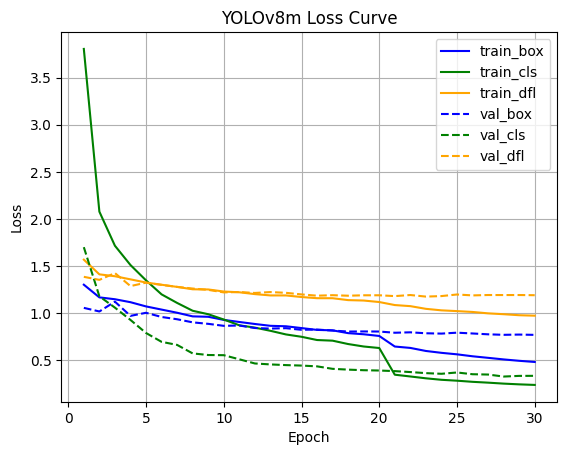

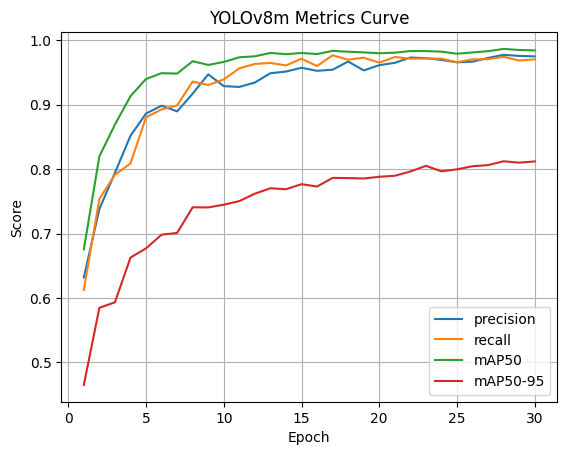

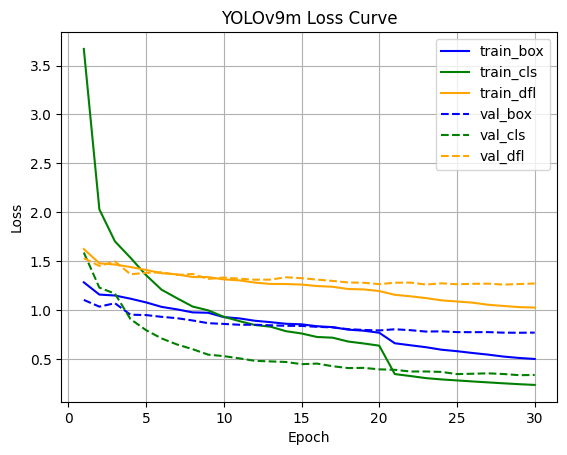

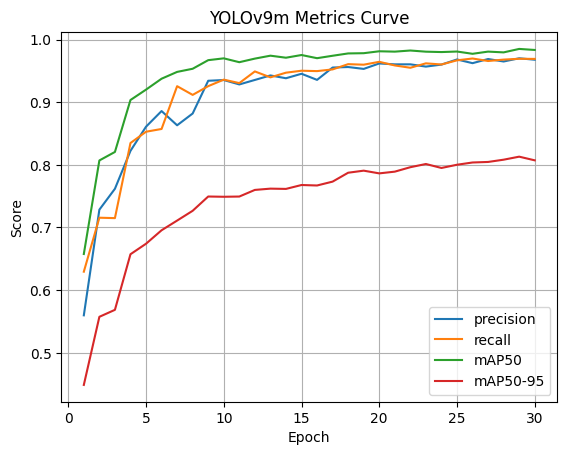

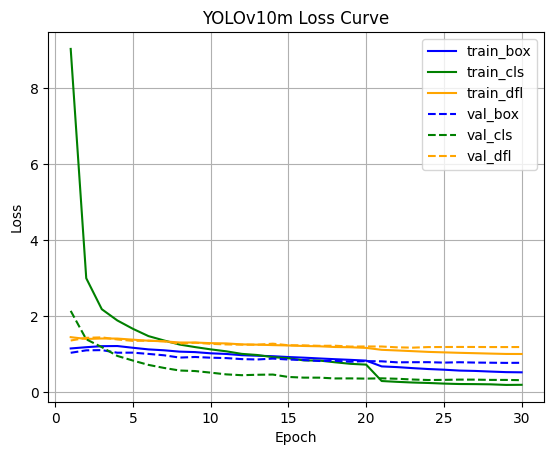

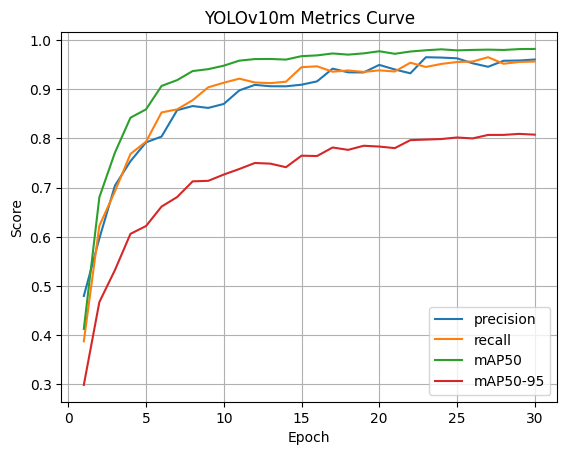

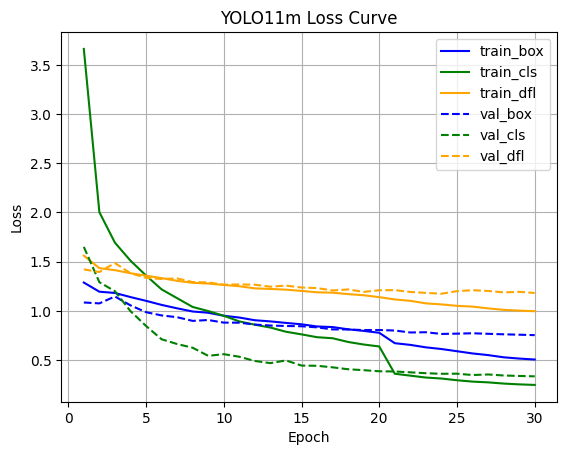

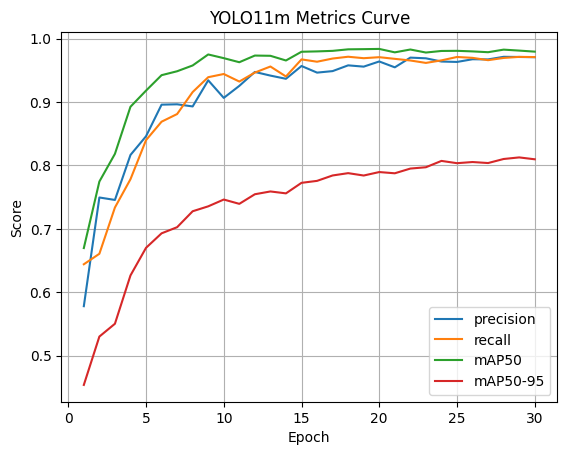

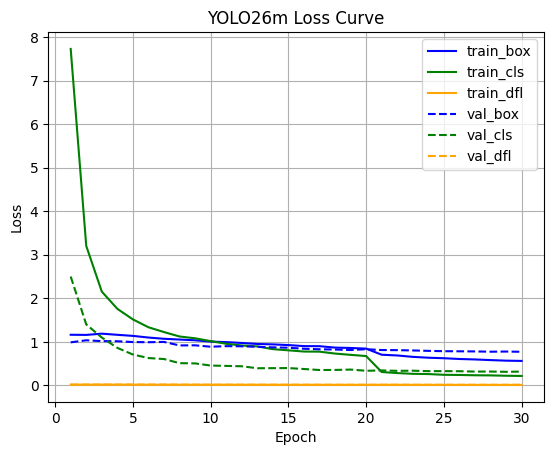

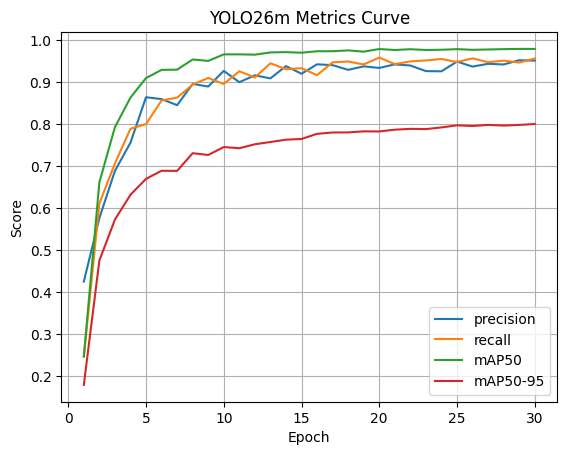

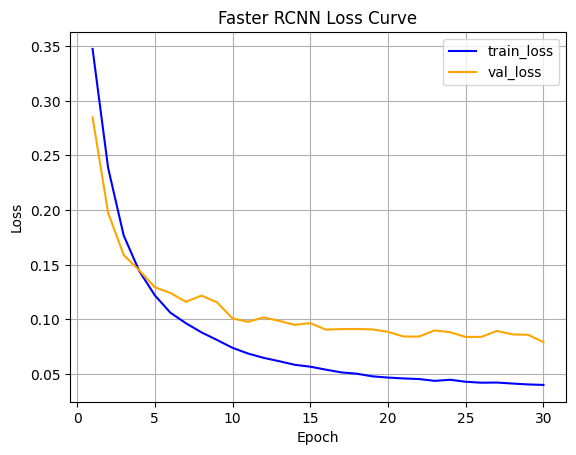

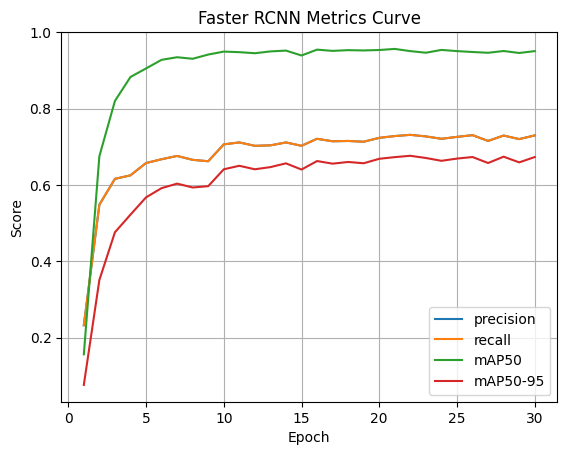

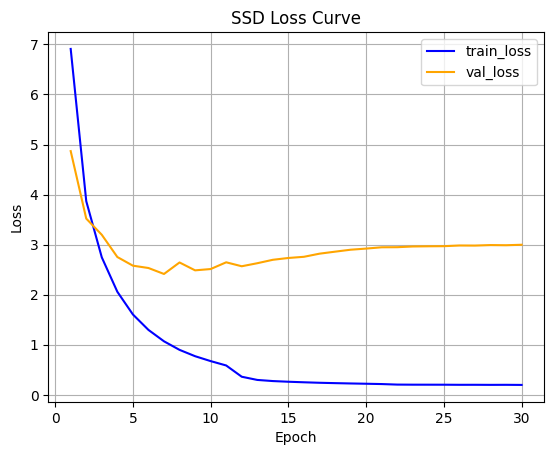

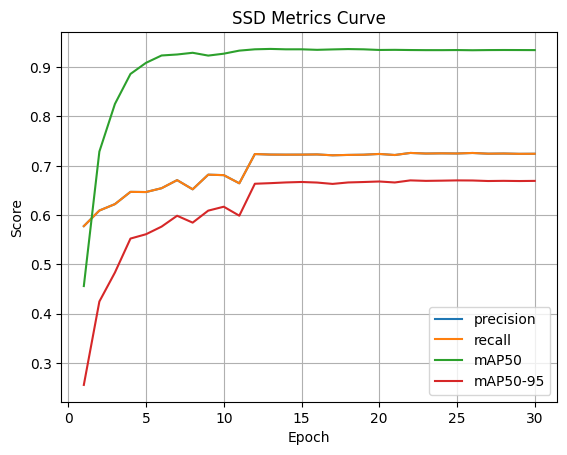

In [12]:
# Plot naming and exact model directory name 
models = {
    'YOLOv8m': 'yolov8m',
    'YOLOv9m': 'yolov9m',
    'YOLOv10m': 'yolov10m',
    'YOLO11m': 'yolo11m',
    'YOLO26m': 'yolo26m',
    'Faster RCNN': 'faster-rcnn',
    'SSD': 'ssd'
}

for name, dirname in models.items():
    result = 'results.csv'
    result_path = os.path.join(TRAIN_RESULT_PATH, dirname, result)
    
    if name not in ('Faster RCNN', 'SSD'):
        plot_training_curves(result_path, name)
    else:
        plot_other_training_curves(result_path, name)

### Plot Combined Model Curves

Model : YOLOv8m


,epoch,train/total_loss,val/total_loss,metrics/mAP50-95(B)
0,1,6.67333,4.13988,0.46523
1,2,4.65481,3.54760,0.58481
2,3,4.25309,3.60360,0.59332
3,4,3.98362,3.18371,0.66270
4,5,3.74234,3.11441,0.67693
29,30,1.69004,2.29180,0.81176


Model : YOLOv9m


,epoch,train/total_loss,val/total_loss,metrics/mAP50-95(B)
0,1,6.57817,4.22415,0.44872
1,2,4.66834,3.71775,0.55743
2,3,4.31856,3.73680,0.56856
3,4,4.09353,3.22866,0.65730
4,5,3.84832,3.12645,0.67406
29,30,1.76249,2.37960,0.80718


Model : YOLOv10m


...

,epoch,train/total_loss,val/total_loss,metrics/mAP50-95(B)
0,1,8.90640,3.50431,0.17921
1,2,4.37675,2.45245,0.47549
2,3,3.35714,2.13151,0.57307
3,4,2.93435,1.89199,0.63220
4,5,2.66665,1.71999,0.67003
29,30,0.78631,1.09952,0.80068


Model : Faster RCNN


,epoch,train/total_loss,val/total_loss,val_map50_95
0,1,0.347433,0.284855,0.076076
1,2,0.238594,0.197503,0.351001
2,3,0.176915,0.159015,0.475938
3,4,0.144386,0.144991,0.522131
4,5,0.122188,0.129492,0.567357
29,30,0.040171,0.079309,0.673016


Model : SSD


,epoch,train/total_loss,val/total_loss,val_map50_95
0,1,6.909275,4.868001,0.255598
1,2,3.868880,3.520249,0.424777
2,3,2.746042,3.196689,0.483529
3,4,2.058802,2.752691,0.552418
4,5,1.605556,2.579823,0.561202
29,30,0.198109,2.997570,0.669401


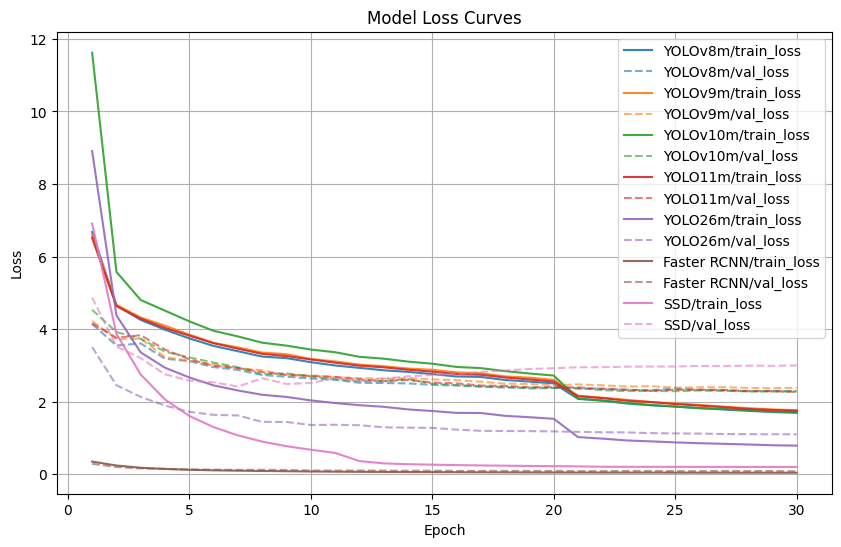

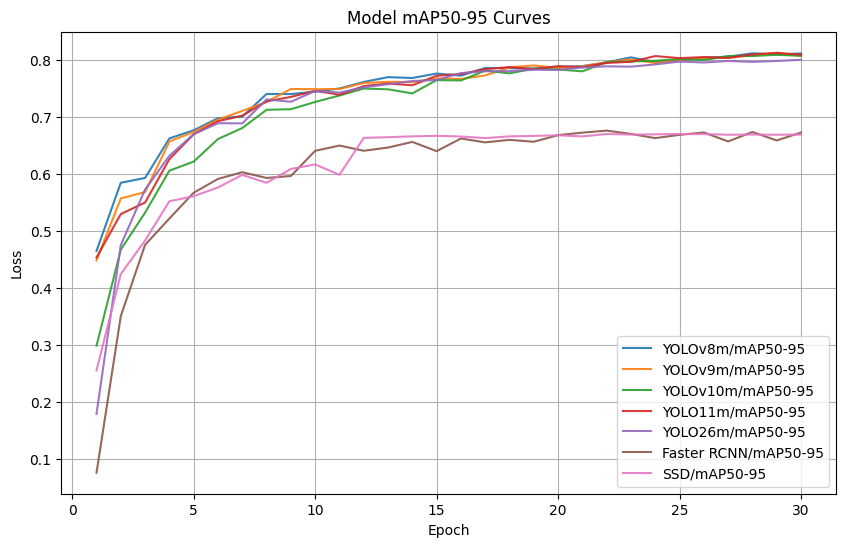

In [37]:
names = list(models.keys())  # Model plot name
dirnames = models.values()
result_paths = [os.path.join(TRAIN_RESULT_PATH, p, result) for p in dirnames]

plot_training_comparison(result_paths, names)

## Test Set Predictions

In [13]:
results_all = []

### YOLO

In [ ]:
for name, dirname in models.items():

    if name in ('Faster RCNN', 'SSD'):
        continue

    print(f'Evaluating {name}')

    weight = 'weights/best.pt'
    weight_path = os.path.join(TRAIN_RESULT_PATH, dirname, weight)

    res = evaluate_model(
        model_path=weight_path,
        model_name=name,
        yaml_path=YAML_PATH,
    )

    res['model'] = name
    results_all.append(res)

### Faster RCNN and SSD

In [15]:
for name, dirname in models.items():
    if name == 'Faster RCNN':
        model = fasterrcnn_resnet50_fpn(num_classes=NUM_CLASSES)
    elif name == 'SSD':
        model = ssd300_vgg16(num_classes=NUM_CLASSES)
    else:
        continue

    print(f'Evaluating {name}')

    weight = 'weights/best.pt'
    weight_path = os.path.join(TRAIN_RESULT_PATH, dirname, weight)
    checkpoint = torch.load(weight_path, map_location=DEVICE, weights_only=True)

    model.load_state_dict(checkpoint['model_state_dict'])

    res = evaluate_other_model(model, name)

    print(res)

    results_all.append(res)

Evaluating Faster RCNN


Test Prediction: 100%|██████████| 717/717 [04:04<00:00,  2.94it/s]


Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.43s).
Accumulating evaluation results...
DONE (t=0.49s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.675
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.941
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.812
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.609
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.688
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.723
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.725
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.725
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

Test Prediction: 100%|██████████| 717/717 [01:32<00:00,  7.79it/s]


Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.77s).
Accumulating evaluation results...
DONE (t=0.40s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.659
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.908
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.787
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.521
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.678
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.698
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.701
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.701
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

## Plot All Model Confusion Matrixs

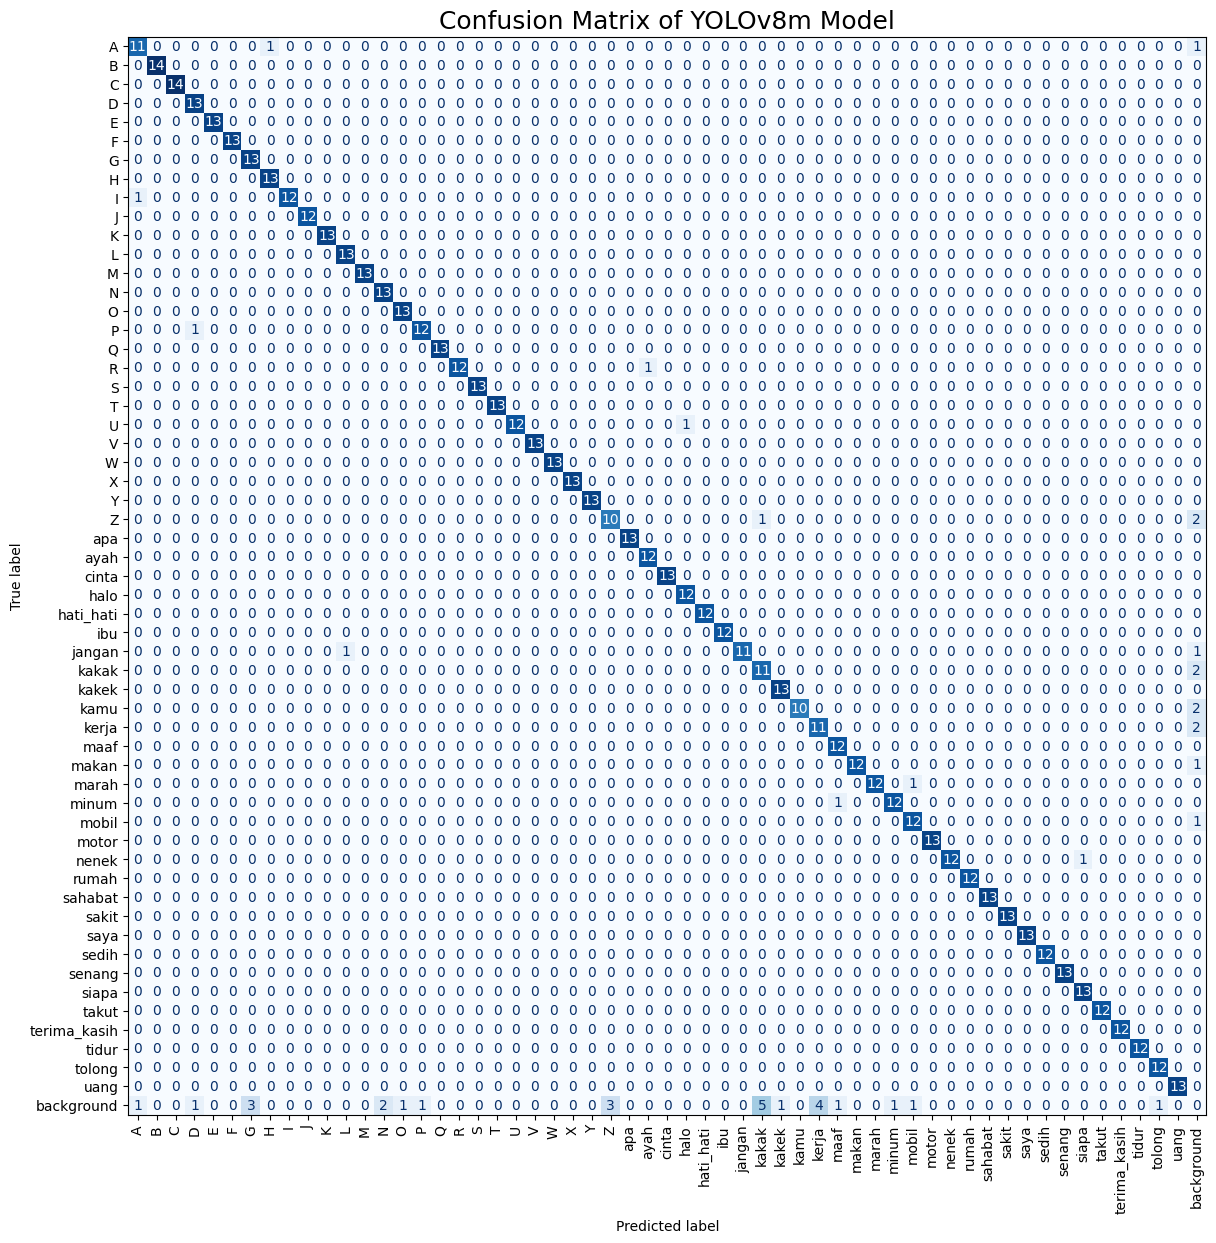

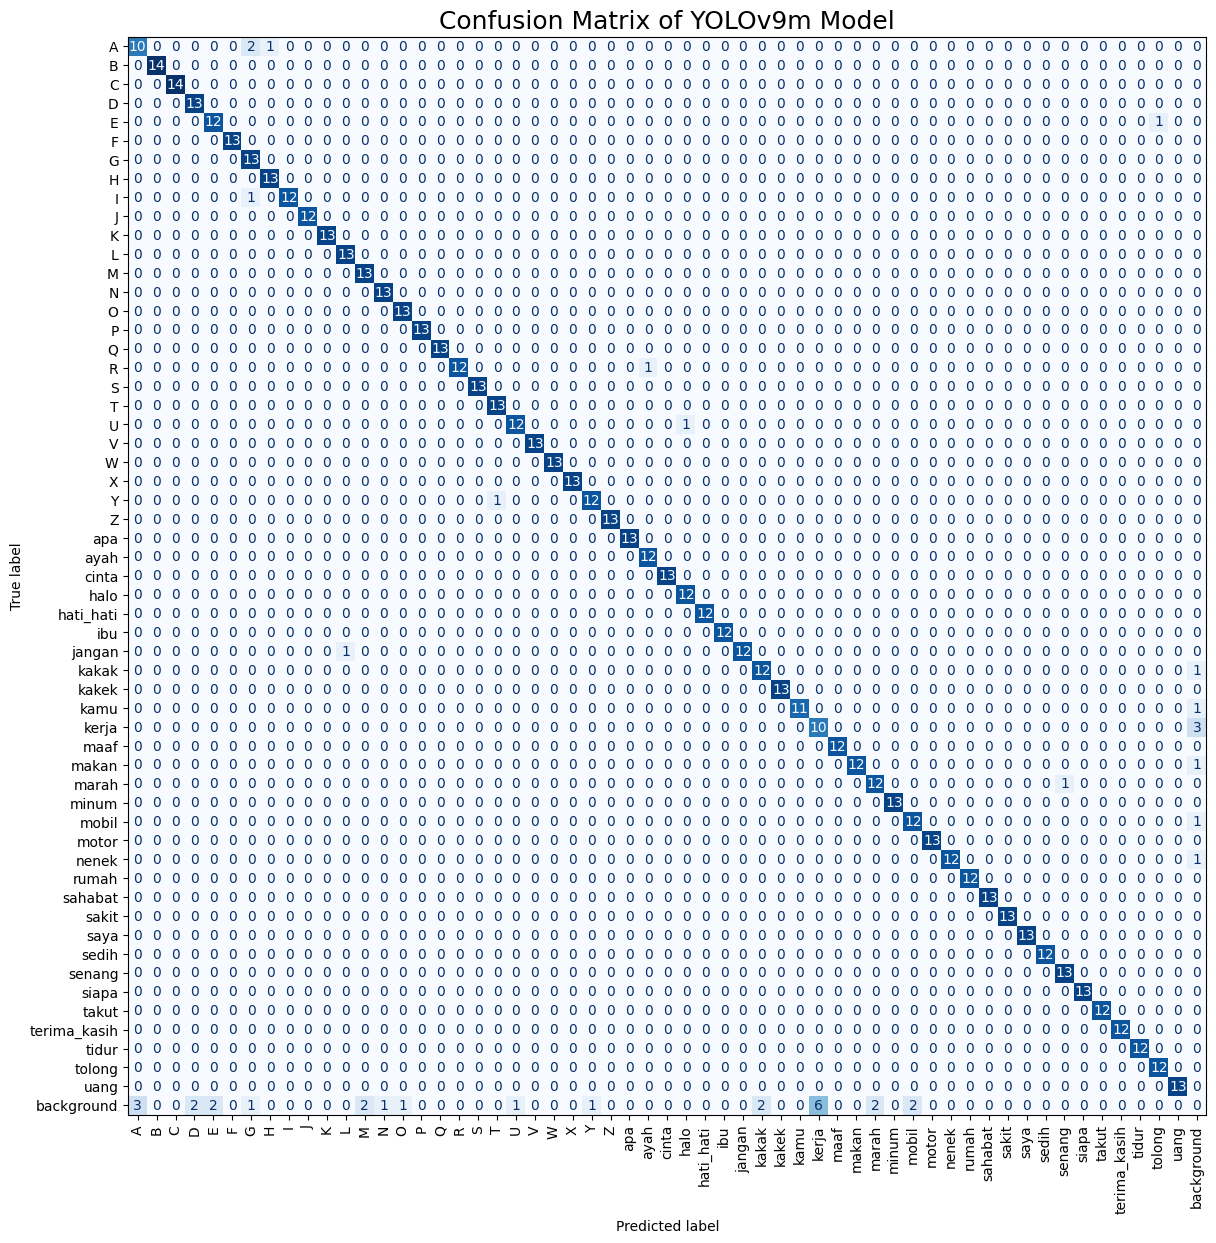

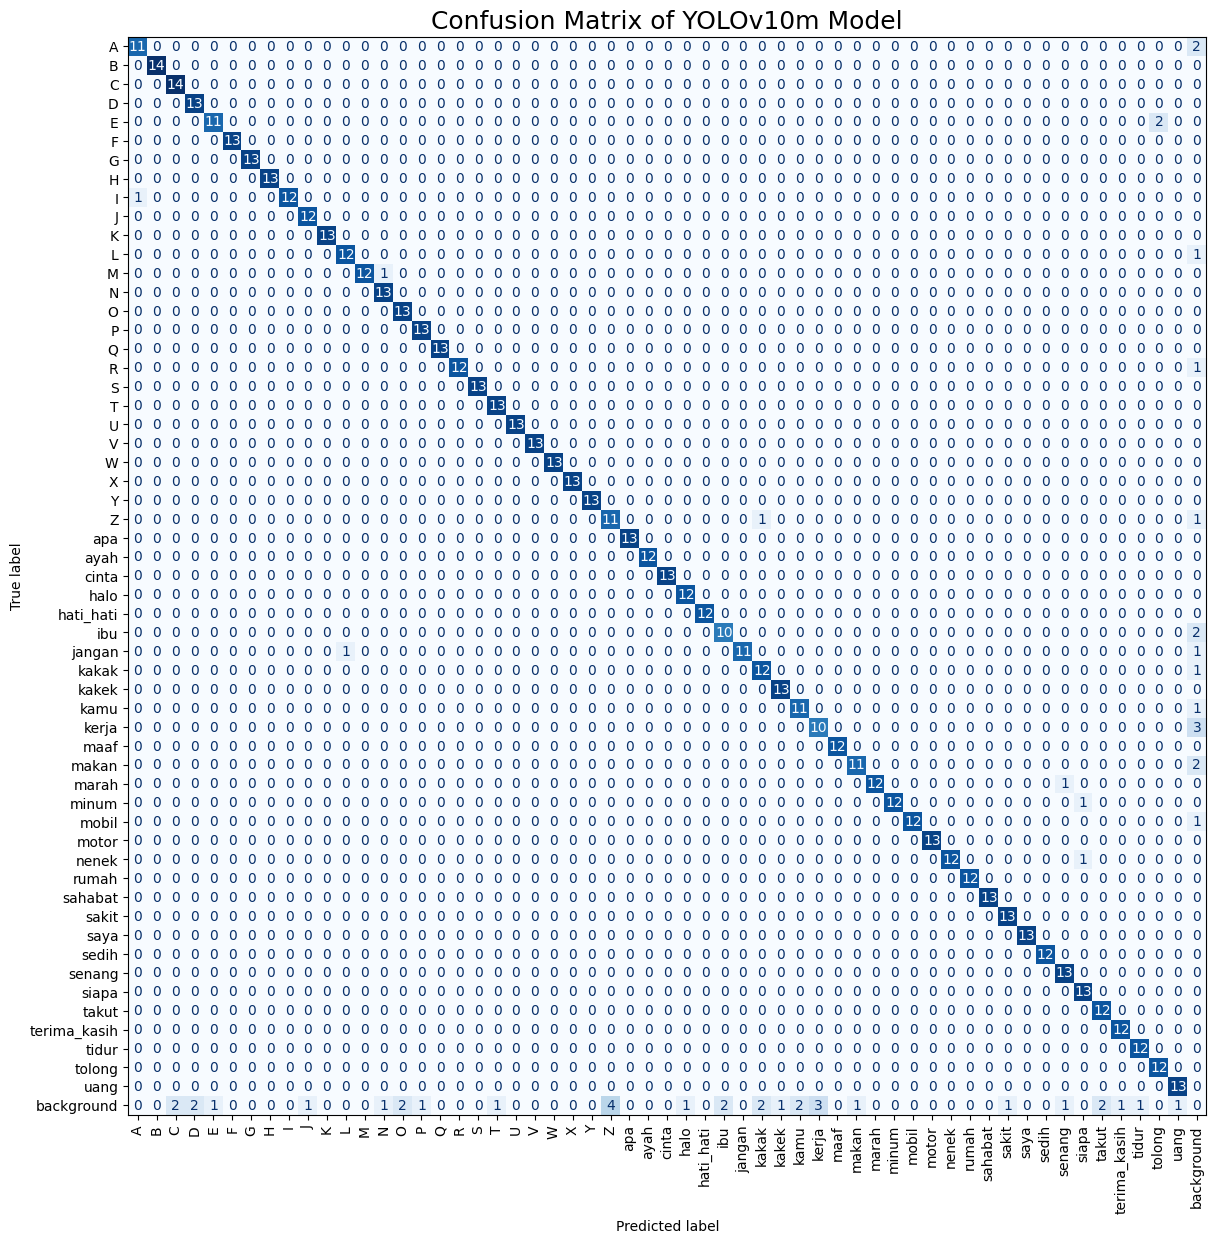

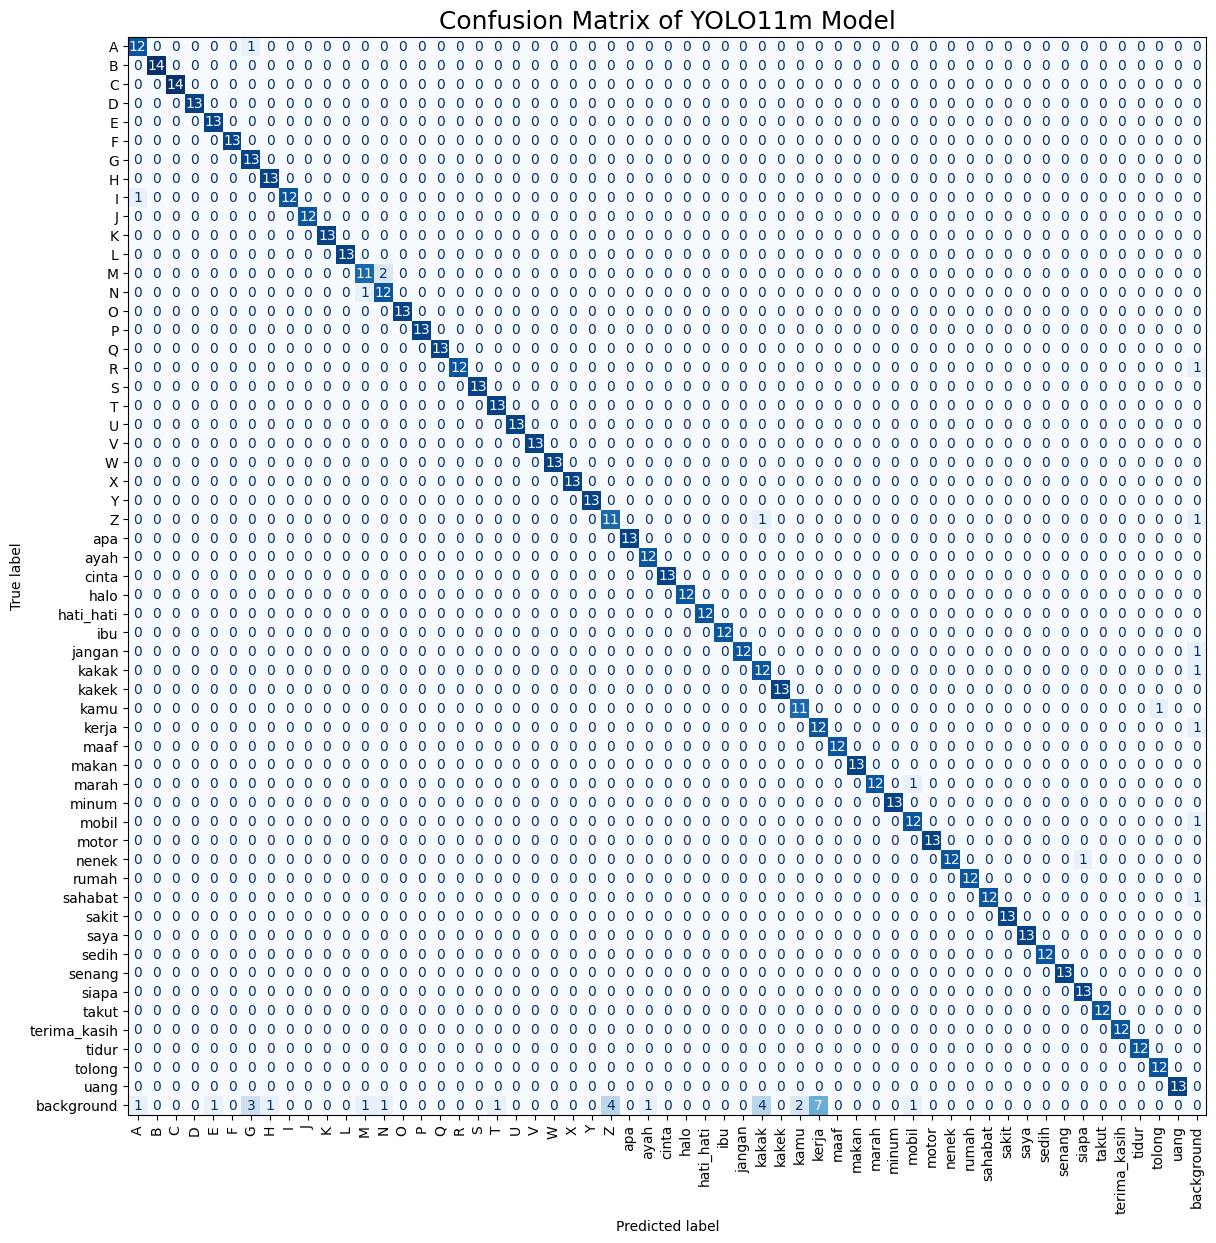

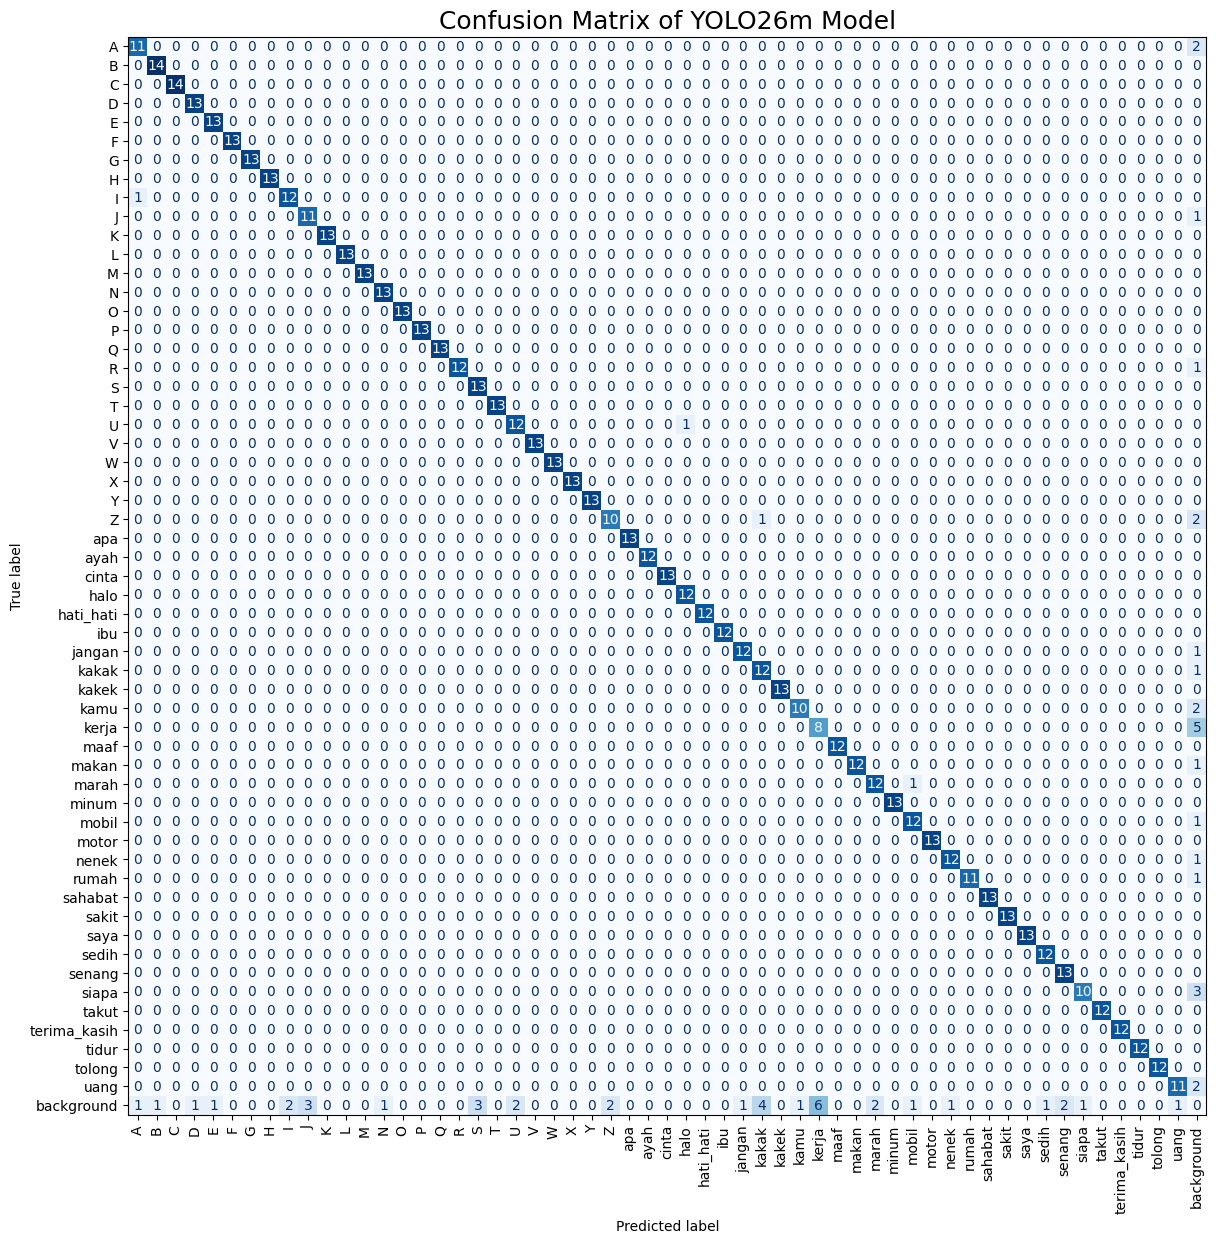

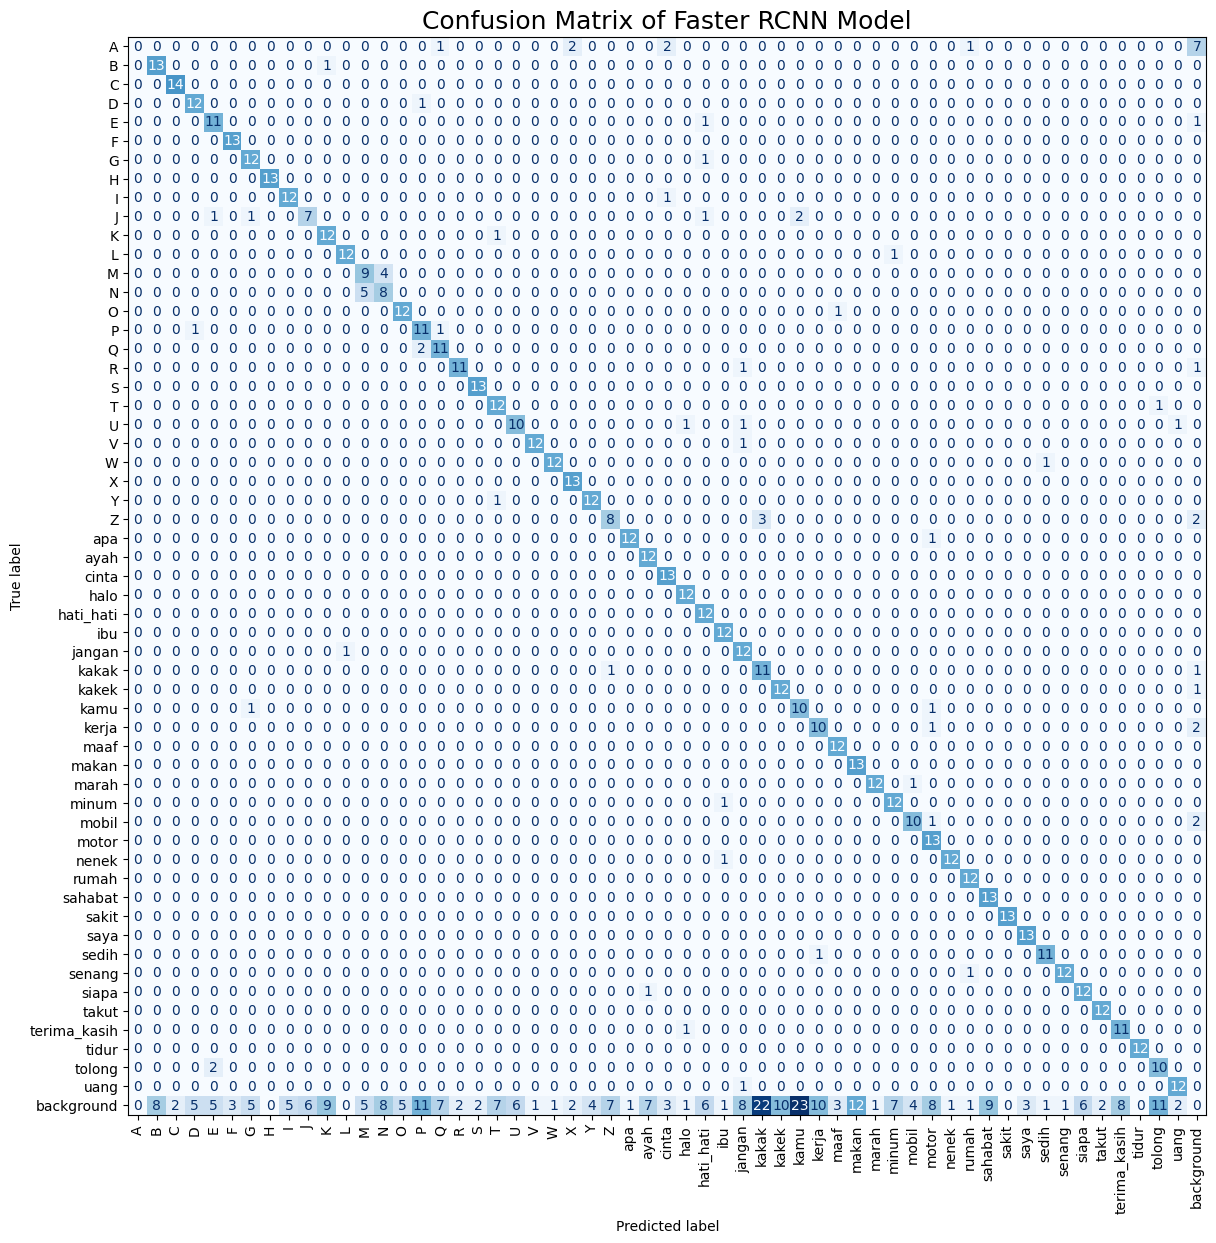

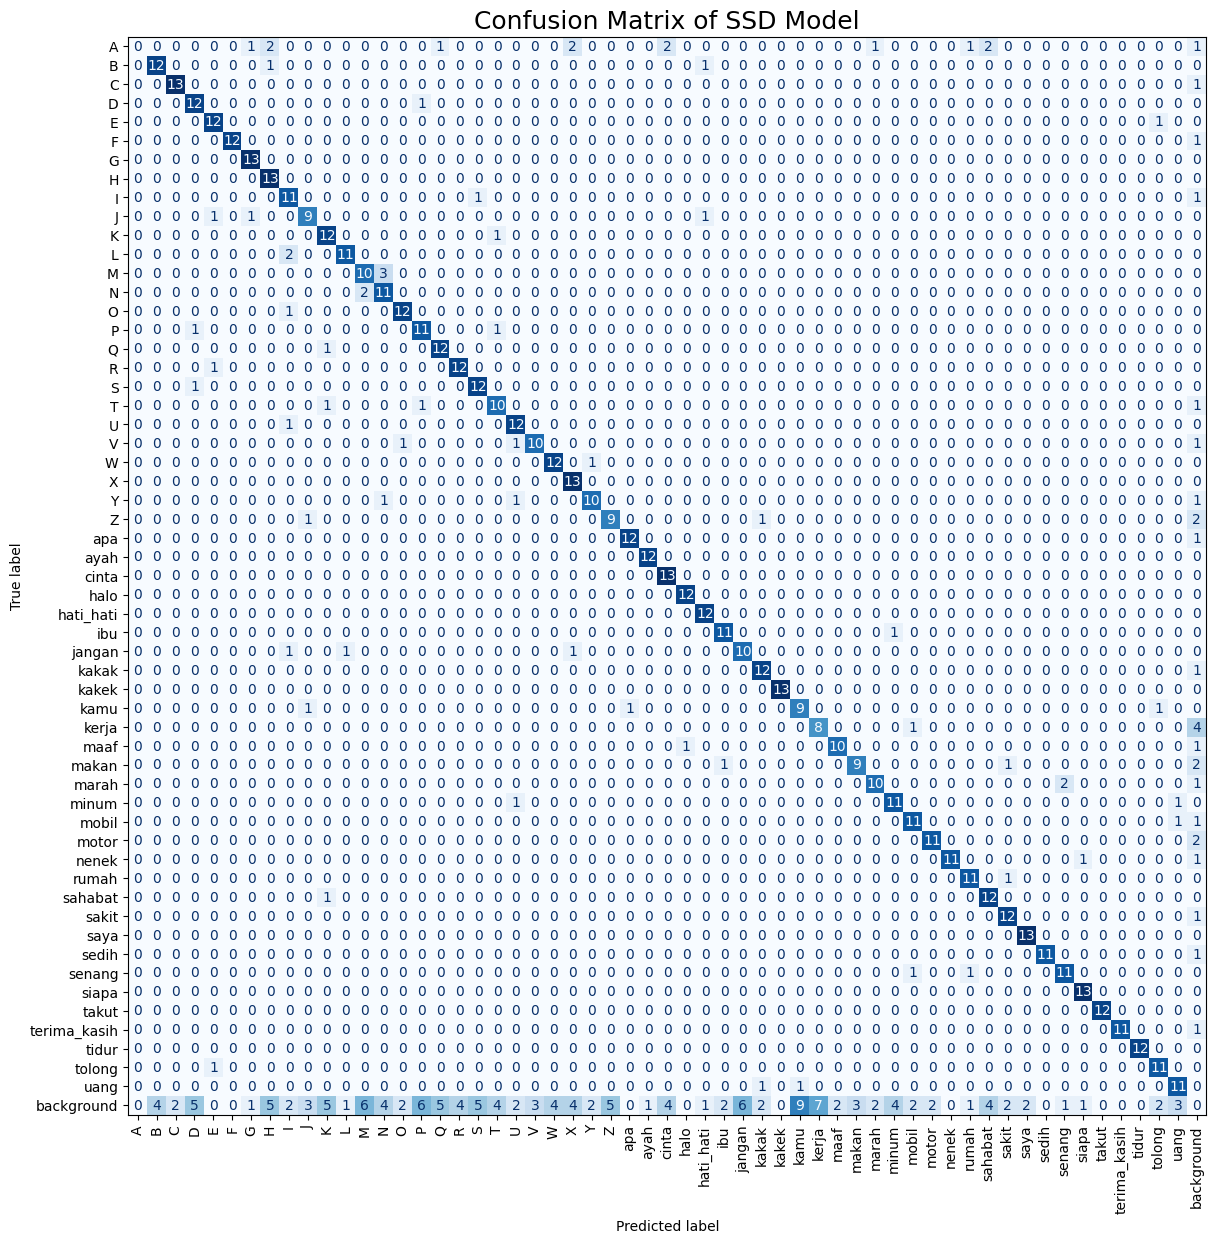

In [16]:
for model_results in results_all:
    model_name = model_results['model']
    confusion = model_results['confusion']
    
    if model_name not in ('Faster RCNN', 'SSD'):
        plot_confusion_matrix(confusion, model_name)
    else:
        plot_other_confusion_matrix(confusion, model_name)

## Combine All Model's Prediction Results

In [17]:
df_compare = pd.DataFrame(results_all)

df_table = df_compare[[
    'model', 'precision', 'recall', 'mAP50', 'mAP50-95', 'f1-score', 'latency'
]]

print(df_table)

         model  precision    recall     mAP50  mAP50-95  f1-score     latency
0      YOLOv8m   0.969732  0.961962  0.979863  0.796589  0.964947   53.638306
1      YOLOv9m   0.971913  0.967594  0.982381  0.803200  0.968858   65.496524
2     YOLOv10m   0.951382  0.955997  0.978508  0.791621  0.952423   55.151249
3      YOLO11m   0.960184  0.968630  0.982511  0.801429  0.963629   66.001376
4      YOLO26m   0.942752  0.950493  0.975948  0.792820  0.945347   66.051787
5  Faster RCNN   0.677965  0.892608  0.941130  0.674755  0.760532  329.660746
6          SSD   0.746235  0.868898  0.907617  0.658874  0.798103  116.336926


## Test Set Prediction Comparison

### Model Metrics Comparison

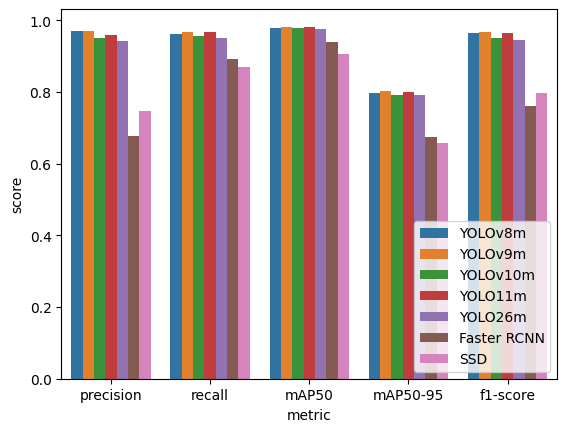

In [18]:
df_evaluation = df_table.drop(columns=['latency'])
df_eva_melt = df_evaluation.melt(
    id_vars='model', var_name='metric', value_name='score'
)

sns.barplot(df_eva_melt, x='metric', y='score', hue='model')
plt.legend(loc='lower right')

plt.show()

### Latency Comparison

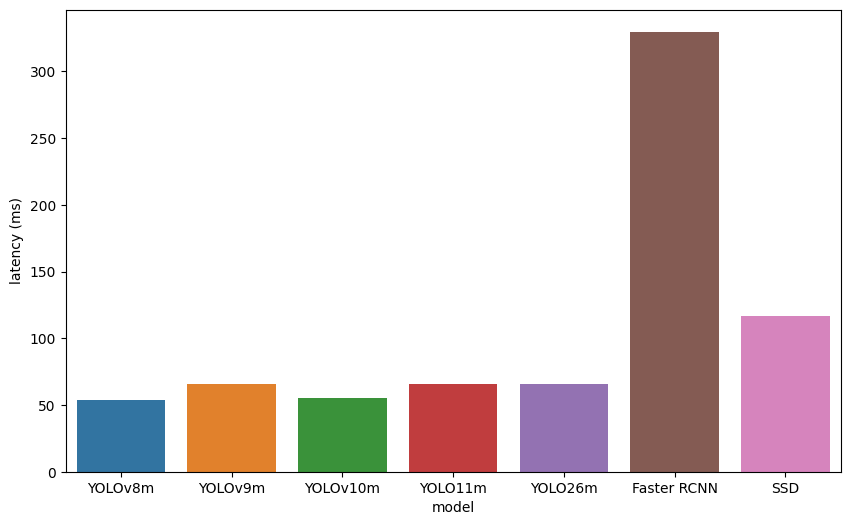

In [19]:
plt.figure(figsize=(10, 6))

sns.barplot(df_table, x='model', y='latency', hue='model')
plt.ylabel('latency (ms)')
plt.show()

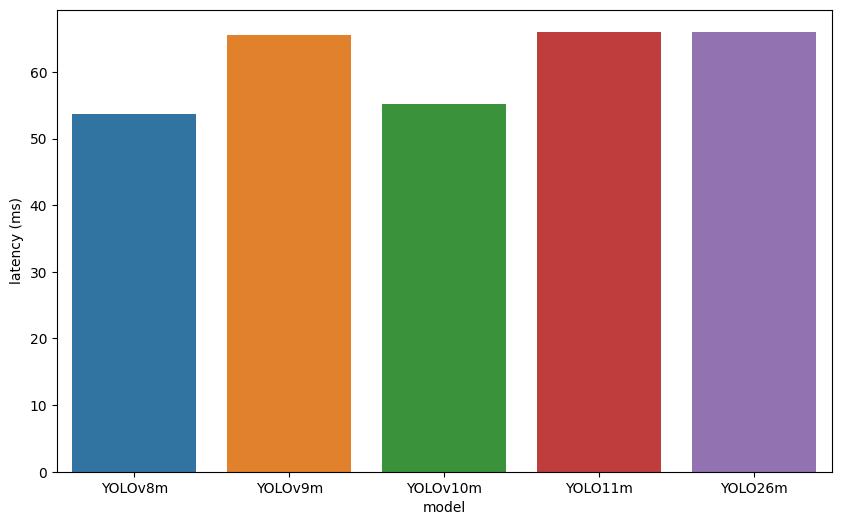

In [21]:
df_yolo = df_table[~df_table['model'].isin(['Faster RCNN', 'SSD'])]

plt.figure(figsize=(10, 6))

sns.barplot(df_yolo, x='model', y='latency', hue='model')
plt.ylabel('latency (ms)')
plt.show()

### mAP50-95 based on Latency Comparison

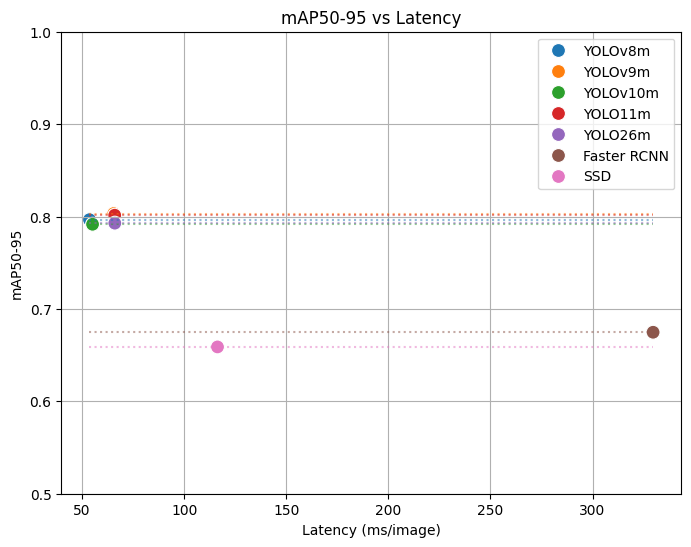

In [27]:
x = df_table['latency']
y = df_table['mAP50-95']
text = df_table['model']

plt.figure(figsize=(8, 6))

ax = sns.scatterplot(
    x=x,
    y=y,
    hue=text,
    s=100
)

leg = ax.legend()
lines = leg.get_lines()

for i in range(len(x)):
    c = lines[i].get_color()
    # plt.text(x[i] + 0.1, y[i] + 0.004, f'{text[i]}', rotation=30, c=c)
    sns.lineplot(x=(min(x), max(x)), y=y[i], c=c, linestyle=':', alpha=0.5)

plt.ylim((0.5, 1))
# plt.xlim(left=0)
# leg.remove()

plt.title("mAP50-95 vs Latency")
plt.xlabel("Latency (ms/image)")
plt.ylabel("mAP50-95")
plt.grid()
plt.show()

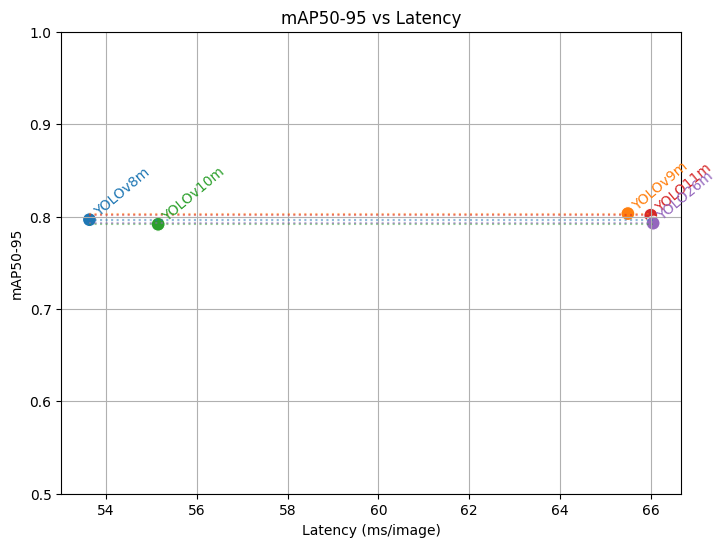

In [ ]:
x = df_yolo['latency']
y = df_yolo['mAP50-95']
text = df_yolo['model']

plt.figure(figsize=(8, 6))

ax = sns.scatterplot(
    x=x,
    y=y,
    hue=text,
    s=100
)

leg = ax.legend()
lines = leg.get_lines()

for i in range(len(x)):
    c = lines[i].get_color()
    plt.text(x[i] + 0.05, y[i] + 0.004, f'{text[i]}', rotation=40, c=c)
    sns.lineplot(x=(min(x), max(x)), y=y[i], c=c, linestyle=':', alpha=0.5)

plt.ylim((0.5, 1))
# plt.xlim(left=0)
leg.remove()

plt.title("mAP50-95 vs Latency")
plt.xlabel("Latency (ms/image)")
plt.ylabel("mAP50-95")
plt.grid()
plt.show()